**Nomes:** 

      Mariana Costa de Mello
      Michelle De Sales Silva

# Conhecimento inicial do conjunto de dados

## Importando as bibliotecas e dados

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

df = pd.read_csv("../data/raw/dupla_08.csv")

In [3]:
df.head()

,indice_01,indice_02,indice_03,indice_04,indice_05,indice_06,indice_07,indice_08,indice_09,classe
0,-6.9563,36.8112,-5620.4606,-3.2781,-1315.2317,17.9246,-7.2672,-5.9521,-4.1154,nivel_alto
1,1.0939,63.9672,14077.7359,-3.3749,-342.5324,2.3080,-8.9664,-3.9209,-5.7741,nivel_alto
2,-11.8757,14.2009,12120.7709,-2.9094,-858.8534,5.0874,-2.6923,-2.7280,-4.7927,nivel_baixo
3,0.9530,7.6380,-2790.4651,-3.2066,-1370.5815,15.1245,-3.9464,-3.8555,-5.6997,nivel_baixo
4,32.1615,7.0609,-16019.3158,-3.1226,-1209.7739,20.0826,-7.8487,-5.4253,-5.6380,nivel_baixo


## Estrutura dos dados

In [4]:
print("Quantidade de registros:", df.shape[0])
print("Atributos previsores:", df.shape[1] - 1)
print("Linhas duplicadas:", df.duplicated().sum())
print()
df.info()

Quantidade de registros: 620
Atributos previsores: 9
Linhas duplicadas: 0

<class 'pandas.DataFrame'>
RangeIndex: 620 entries, 0 to 619
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   indice_01  620 non-null    float64
 1   indice_02  620 non-null    float64
 2   indice_03  620 non-null    float64
 3   indice_04  620 non-null    float64
 4   indice_05  620 non-null    float64
 5   indice_06  620 non-null    float64
 6   indice_07  620 non-null    float64
 7   indice_08  620 non-null    float64
 8   indice_09  620 non-null    float64
 9   classe     620 non-null    str    
dtypes: float64(9), str(1)
memory usage: 54.9 KB


In [5]:
print("valores nulos por coluna:")
print(df.isna().sum().to_string())

valores nulos por coluna:
indice_01    0
indice_02    0
indice_03    0
indice_04    0
indice_05    0
indice_06    0
indice_07    0
indice_08    0
indice_09    0
classe       0


## Variável alvo

In [6]:
contagem = df["classe"].value_counts()
proporcao = df["classe"].value_counts(normalize=True)
pd.DataFrame({"quantidade": contagem, "proporção": proporcao})

,quantidade,proporção
classe,,
nivel_baixo,316,0.5097
nivel_alto,304,0.4903


## Atributos e escala

In [7]:
X_all = df.drop(columns="classe")
resumo = X_all.describe().T
resumo["amplitude"] = resumo["max"] - resumo["min"]
resumo["assimetria"] = X_all.skew()
resumo

,count,mean,std,min,25%,50%,75%,max,amplitude,assimetria
indice_01,620.0000,2.1417,46.7493,-121.6752,-28.2454,-0.7174,35.8201,152.4152,274.0904,0.1533
indice_02,620.0000,-2.2879,20.5970,-82.7848,-16.2057,-2.0541,10.4924,63.9672,146.7520,-0.0310
indice_03,620.0000,5209.0373,16035.9680,-35466.1407,-6722.1375,5637.5975,16169.8710,46943.3679,82409.5085,0.0586
indice_04,620.0000,-3.3048,0.3078,-4.2969,-3.5029,-3.2909,-3.1090,-2.4413,1.8556,-0.1392
indice_05,620.0000,-757.1382,790.4514,-3031.6459,-1253.3531,-790.3274,-288.0467,1662.2973,4693.9432,0.1762
indice_06,620.0000,6.9503,8.0542,-14.4694,0.9357,7.0342,12.6786,26.8467,41.3161,0.0166
indice_07,620.0000,-3.9431,4.8738,-20.4114,-7.2647,-3.8766,-0.4367,11.5541,31.9655,-0.1881
indice_08,620.0000,-4.2002,2.1903,-12.4703,-5.5435,-3.9715,-2.7226,3.4246,15.8949,-0.3523
indice_09,620.0000,-5.5216,1.5707,-10.6930,-6.5818,-5.5798,-4.5118,0.3514,11.0444,0.0683


razão entre o maior e o menor desvio padrão: 52107


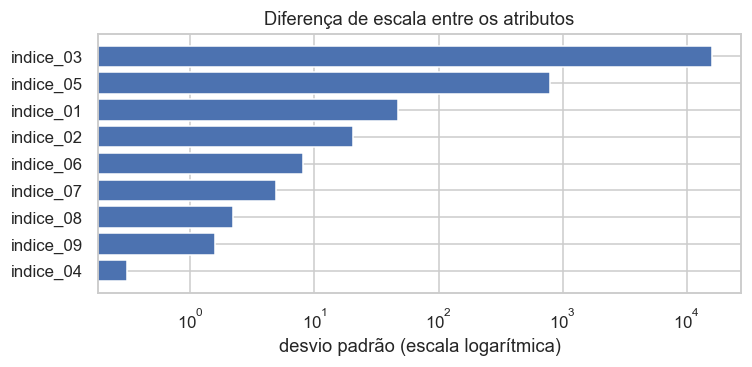

In [8]:
desvios = X_all.std().sort_values()
print("razão entre o maior e o menor desvio padrão: %.0f" % (desvios.max() / desvios.min()))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(desvios.index, desvios.values, color="#4C72B0")
ax.set_xscale("log")
ax.set_xlabel("desvio padrão (escala logarítmica)")
ax.set_title("Diferença de escala entre os atributos")
plt.tight_layout()
plt.show()

In [9]:
rng = np.random.default_rng(0)
pares = rng.integers(0, len(X_all), size=(5000, 2))
dif2 = (X_all.values[pares[:, 0]] - X_all.values[pares[:, 1]]) ** 2
contribuicao = pd.Series(dif2.mean(axis=0) / dif2.mean(axis=0).sum(), index=X_all.columns)
(contribuicao * 100).round(3).rename("% da distância quadrática").to_frame()

,% da distância quadrática
indice_01,0.0010
indice_02,0.0000
indice_03,99.7580
indice_04,0.0000
indice_05,0.2410
indice_06,0.0000
indice_07,0.0000
indice_08,0.0000
indice_09,0.0000


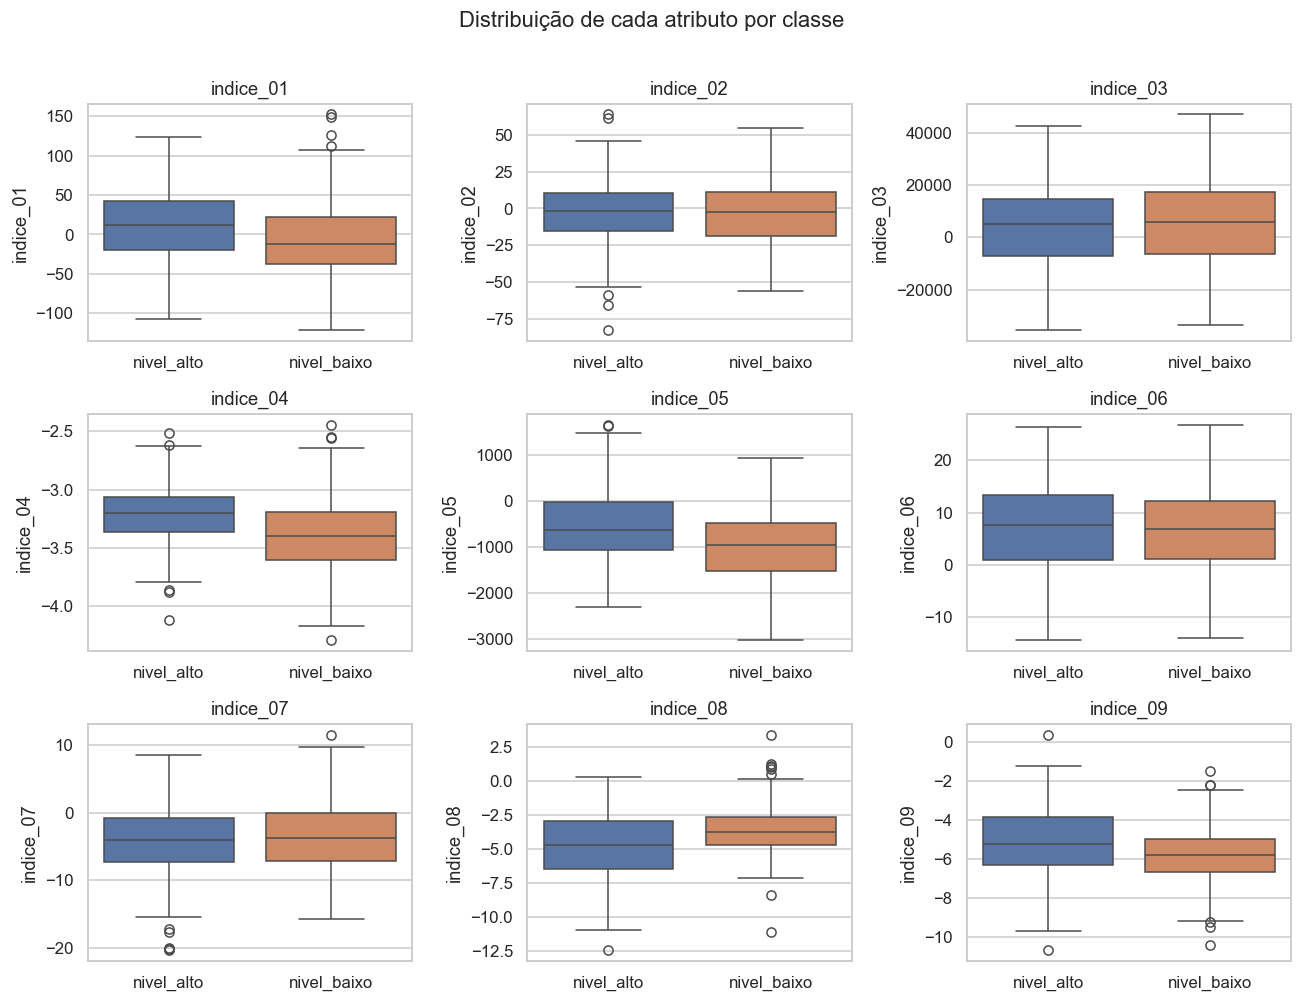

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), X_all.columns):
    sns.boxplot(data=df, x="classe", y=col, hue="classe", ax=ax,
                palette=["#4C72B0", "#DD8452"], legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribuição de cada atributo por classe", y=1.01)
plt.tight_layout()
plt.show()

In [11]:
Z = (X_all - X_all.mean()) / X_all.std()
dif_classes = (Z[df["classe"] == "nivel_alto"].mean() - Z[df["classe"] == "nivel_baixo"].mean())
dif_classes.rename("diferença de médias (em desvios padrão)").sort_values().to_frame()

,diferença de médias (em desvios padrão)
indice_08,-0.5255
indice_07,-0.1363
indice_03,-0.1352
indice_02,0.0054
indice_06,0.0495
indice_01,0.3918
indice_09,0.4345
indice_04,0.5796
indice_05,0.5914


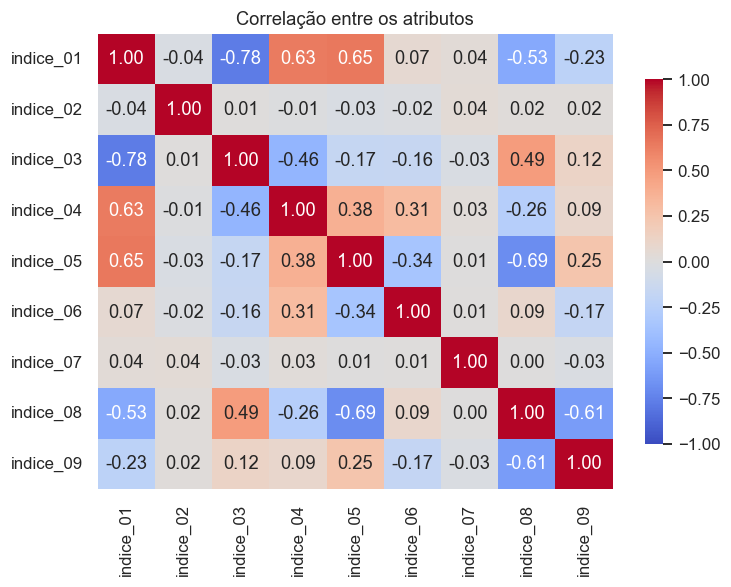

In [12]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(X_all.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlação entre os atributos")
plt.tight_layout()
plt.show()

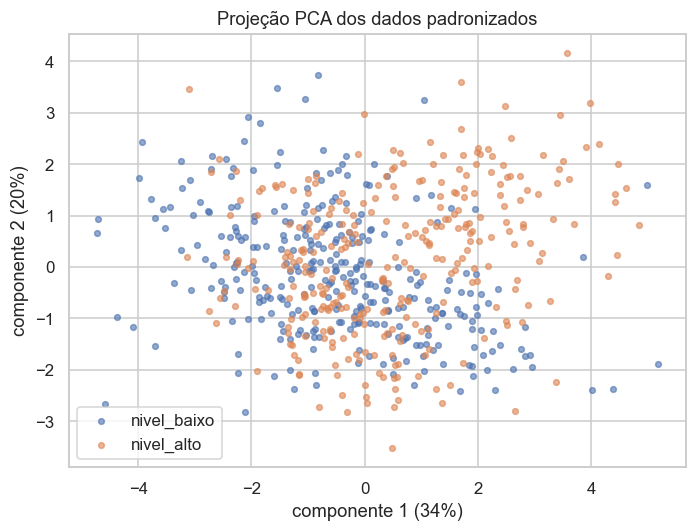

In [13]:

pca = PCA(n_components=2).fit(Z)
proj = pca.transform(Z)
fig, ax = plt.subplots(figsize=(6.5, 5))
for nome, cor in [("nivel_baixo", "#4C72B0"), ("nivel_alto", "#DD8452")]:
    m = (df["classe"] == nome).values
    ax.scatter(proj[m, 0], proj[m, 1], s=14, alpha=.6, c=cor, label=nome)
ax.set_xlabel(f"componente 1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"componente 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Projeção PCA dos dados padronizados")
ax.legend()
plt.tight_layout()
plt.show()

## Resultados da Análise exploratória

* `indice_03` domina a distância (99,8%), mas separa pouco as classes.
* `indice_05`, `indice_04`, `indice_08` e `indice_09` são os que mais diferenciam as classes.
* Há correlação entre alguns atributos, fazendo com que tenham peso duplicado na distância.
* As classes se sobrepõem bastante, então não esperamos uma acurácia próxima de 100%.
* São 620 linhas e 9 atributos numéricos, com 2 classes equilibradas (51%/49%).